# Parte 1 — Stages A, B e C: BoVW + SVM linear

Este notebook segue a estrutura do `1_handcraft.ipynb` original, com estas alterações:

1. **Corrigido o `IndentationError`** (espaço antes de `encoding = ...`).
2. **Categoria `motorbike`**, como pede a Stage B.
3. **Split de validação** criado a partir do treino (80/20, estratificado, seed fixa).
   O subset `"val"` dos ficheiros é usado como **teste** e só é avaliado uma vez, na Stage C.
4. **`remove_spatial_information` local**, porque a função de `encoders.py` agrupa os tiles
   de forma errada para o layout produzido por `encode_tiling` (blocos `[tile0 | tile1 | tile2 | tile3]`).
5. **Pesos do SVM "dobrados" corretamente** antes de chamar `RelevantVisualWordsDisplay`,
   pelo mesmo motivo do ponto 4.
6. Removidas as células de debug no fim (`os.listdir`).

**Referências principais:** Sivic & Zisserman (2003); Csurka et al. (2004); Lazebnik et al. (2006);
documentação do scikit-learn (`LinearSVC`, `average_precision_score`, `train_test_split`).

In [1]:
import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import average_precision_score
from sklearn.model_selection import train_test_split

from src import utils, encoders
from src.visualization import displayRankedImageList, displayPrecisionRecallCurve
from src.visualization import RelevantVisualWordsDisplay

SEED = 42  # uma única seed para tudo o que é aleatório -> resultados reproduzíveis


def loadEncodingSubset(category, encoding, subset="train", root_dir="data"):
    base_dir = f"{root_dir}/encodings/{encoding}/"
    pos_file = f"{base_dir}/{category}_{subset}.npz"
    neg_file = f"{base_dir}/background_{subset}.npz"

    p_data = np.load(pos_file)
    p_hist, p_name = p_data['histograms'], p_data['file_names']
    p_label = np.ones(len(p_name), dtype=np.int32)

    n_data = np.load(neg_file)
    n_hist, n_name = n_data['histograms'], n_data['file_names']
    n_label = -np.ones(len(n_name), dtype=np.int32)

    hist = np.concatenate([p_hist, n_hist], axis=0)
    names = np.concatenate([p_name, n_name], axis=0)
    labels = np.concatenate([p_label, n_label], axis=0)

    return hist, labels, names


def get_subset(histograms, names, labels, fraction):
    # Mantida do original; vai ser usada na Stage G (com seed nessa altura).
    num_images = len(labels)
    if np.isinf(fraction):
        num_selected = num_images
    elif fraction < 1:
        num_selected = int(np.ceil(fraction * num_images))
    else:
        num_selected = int(fraction)

    rng = np.random.default_rng()
    sel = rng.choice(num_images, size=num_selected, replace=False)
    names = [names[i] for i in sel]
    histograms = histograms[sel, :]
    labels = labels[sel]
    return histograms, names, labels


def printDatasetStats(histograms, names, labels, subset="train"):
    print("Number of {:5s} images: {:5d} positive ({:.2%}), {:5d} negative ({:.2%}), total: {:5d}".format(subset,
        sum(labels > 0),
        sum(labels > 0)/len(labels),
        sum(labels < 0),
        sum(labels < 0)/len(labels),
        len(labels)
        )
    )


def l2norm(x):
    return x/(np.sum(x**2, axis=1, keepdims=True)**0.5 + 1e-10)  # l2 norm


def l1norm(x):
    # np.abs para a função continuar correta com VLAD/FV, que têm valores negativos
    return x / (np.sum(np.abs(x), axis=1, keepdims=True) + 1e-10)


def remove_spatial_information(histograms, num_tiles=4):
    # encode_tiling concatena os tiles em blocos: [tile0 (K) | tile1 (K) | tile2 (K) | tile3 (K)].
    # reshape(N, 4, K) põe um tile por linha; a média sobre os tiles dá o histograma global / 4.
    # (Dividir por 4 não importa: a normalização seguinte cancela essa constante.)
    num_images = histograms.shape[0]
    return histograms.reshape(num_images, num_tiles, -1).mean(axis=1)


def split_train_val(histograms, labels, names, val_fraction=0.2, seed=SEED):
    # stratify=labels mantém a mesma proporção positivos/negativos nos dois subconjuntos.
    # Devolve: x_train, x_val, y_train, y_val, names_train, names_val
    return train_test_split(histograms, labels, names, test_size=val_fraction,
                            stratify=labels, random_state=seed)


def show_examples(names, labels, category, n=6, seed=SEED):
    """Mostra n imagens positivas (linha de cima) e n negativas (linha de baixo)."""
    rng = np.random.default_rng(seed)
    positives = rng.choice(np.flatnonzero(labels > 0), size=n, replace=False)
    negatives = rng.choice(np.flatnonzero(labels < 0), size=n, replace=False)

    fig, axes = plt.subplots(2, n, figsize=(2.5 * n, 5))
    for row, (indices, title) in enumerate([(positives, category), (negatives, "background")]):
        for ax, i in zip(axes[row], indices):
            ax.imshow(Image.open(f"data/images/{names[i]}.jpg"))
            ax.set_title(title)
            ax.axis("off")
    plt.tight_layout()
    plt.show()


def evaluate_ap(x_train, y_train, x_eval, y_eval, C=10):
    """Treina um SVM linear e devolve (AP no conjunto de avaliação, tempo de treino em s)."""
    start = time.perf_counter()
    W, b = utils.train_svm(x_train, y_train, C=C)
    train_time = time.perf_counter() - start

    scores = W @ x_eval.T + b
    return average_precision_score(y_eval, scores), train_time

# Stage A: Data Preparation

**O que se faz aqui:**
1. Carregar as encodings BoVW já calculadas (`bovw_K512_C0`: K=512 palavras, sem PCA, 4 tiles → 2048 dimensões).
2. Separar **treino / validação / teste**:
   - os ficheiros só têm `train` e `val`;
   - o `val` dos ficheiros passa a ser o **teste** (usado uma única vez, na Stage C);
   - a **validação** sai de 20% do treino. É nela que se comparam configurações
     (vocabulário, tiling), como manda o protocolo do enunciado.
3. Inspecionar imagens positivas e negativas (variação de escala, pose, fundo).
4. Normalizar (L2), porque com L2 o kernel linear passa a ser a similaridade de cosseno.


Encoding : bovw_K512_C0
Category: motorbike
Encoding Size: 2048
Number of train images:    96 positive (10.54%),   815 negative (89.46%), total:   911
Number of val   images:    24 positive (10.53%),   204 negative (89.47%), total:   228
Number of test  images:   125 positive (10.40%),  1077 negative (89.60%), total:  1202


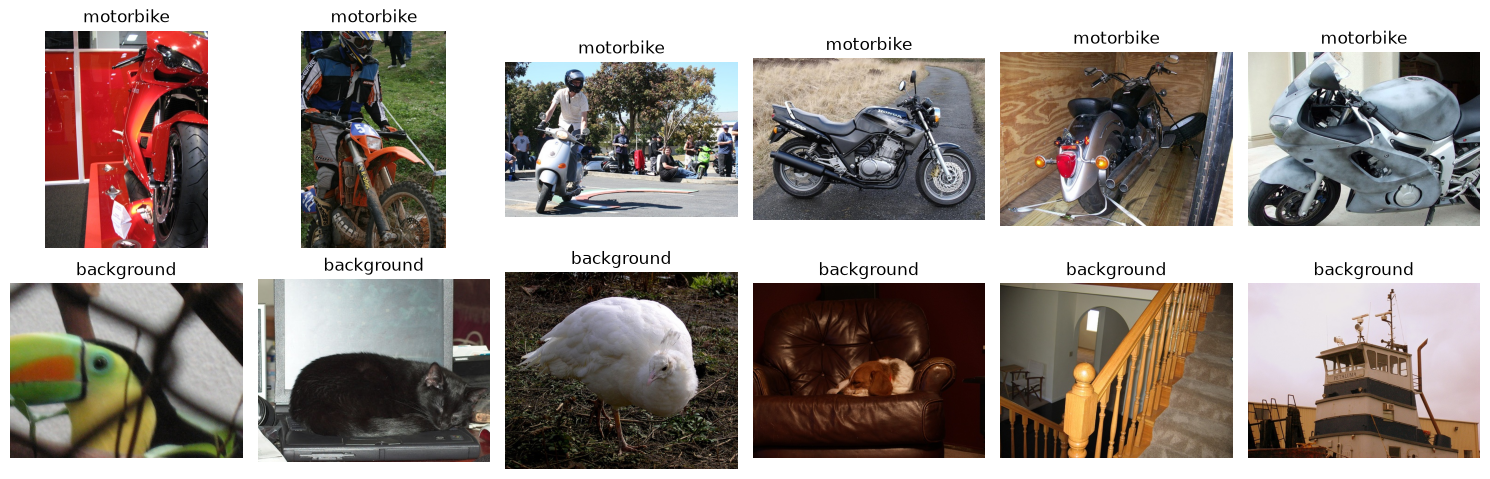

Training histograms shape: (911, 2048)
Validation histograms shape: (228, 2048)
Testing histograms shape: (1202, 2048)


In [2]:
#encoding = "bovw_K512_C0"
#encoding = "vlad_K32_C80"
#encoding = "fv_K32_C80"
encoding = "bovw_K512_C0"

category = "motorbike"
#category = "aeroplane"
#category = "person"

# Load training data
histograms, labels, names = loadEncodingSubset(category, encoding, subset="train")

# Load testing data (o subset "val" dos ficheiros é o nosso TESTE)
testHistograms, testLabels, testNames = loadEncodingSubset(category, encoding, subset="val")

################################################################################
# Create a validation split from the training data
################################################################################
trainHist, valHist, trainLabels, valLabels, trainNames, valNames = split_train_val(
    histograms, labels, names
)

################################################################################
# Throw away part of the training data (Stage G)
################################################################################
# trainHist, trainNames, trainLabels = get_subset(trainHist, trainNames, trainLabels, 0.1)
# trainHist, trainNames, trainLabels = get_subset(trainHist, trainNames, trainLabels, 0.5)

################################################################################
# Show some statistics about the dataset
################################################################################
print("Encoding : {}\nCategory: {}\nEncoding Size: {}".format(encoding, category, trainHist.shape[1]))
printDatasetStats(trainHist, trainNames, trainLabels, subset="train")
printDatasetStats(valHist, valNames, valLabels, subset="val")
printDatasetStats(testHistograms, testNames, testLabels, subset="test")

# Inspect representative images
show_examples(trainNames, trainLabels, category)

################################################################################
# Vary the image representation
################################################################################
# trainHist = remove_spatial_information(trainHist)
# valHist = remove_spatial_information(valHist)
# testHistograms = remove_spatial_information(testHistograms)

################################################################################
# Vary the classifier (Hellinger kernel) -> Stage F
################################################################################
# ** insert code here for the Hellinger kernel using  **
# ** the training histograms and testHistograms       **

# L2 normalize the histograms before running the linear SVM
trainHist = l2norm(trainHist)
valHist = l2norm(valHist)
testHistograms = l2norm(testHistograms)

print("Training histograms shape:", trainHist.shape)
print("Validation histograms shape:", valHist.shape)
print("Testing histograms shape:", testHistograms.shape)

## Stage A: vocabulário (K) e tiling vs histograma global

O enunciado pede pelo menos **dois tamanhos de vocabulário adicionais** e a comparação **tiling 2×2 vs global**.
As encodings de K=256 e K=1024 **não vêm feitas**; gera-as no terminal, na raiz do projeto
(`-m` porque `train.py` e `extract.py` usam imports relativos ao pacote `src`):

```bash
# 1) treinar os encoders (k-means sobre descritores de treino). --cache-dir guarda o SIFT para reutilizar
python -m src.train -e bovw -k 256  --cache-dir cache/
python -m src.train -e bovw -k 1024 --cache-dir cache/

# 2) codificar todas as imagens com cada encoder
python -m src.extract -e data/encoders/bovw_K256_C0.npz
python -m src.extract -e data/encoders/bovw_K1024_C0.npz
```

O k-means com K=1024 sobre ~300 mil descritores de 128 dimensões demora (minutos a dezenas de minutos, conforme o CPU).

A célula seguinte avalia todas as combinações **na validação**. Encodings que ainda não existam são saltadas.

In [3]:
results = []

for enc in ["bovw_K256_C0", "bovw_K512_C0", "bovw_K1024_C0"]:
    if not os.path.exists(f"data/encodings/{enc}/{category}_train.npz"):
        print(f"{enc}: encodings em falta, a saltar (ver comandos acima).")
        continue

    hist, lab, nam = loadEncodingSubset(category, enc, subset="train")
    # Os ficheiros de todas as encodings têm as imagens pela mesma ordem, por isso
    # o split com a mesma seed dá exatamente as mesmas imagens de treino/validação.
    assert np.array_equal(nam, names), "ordem das imagens diferente entre encodings"
    x_tr, x_val, y_tr, y_val, _, _ = split_train_val(hist, lab, nam)

    for spatial in (True, False):
        xt = x_tr if spatial else remove_spatial_information(x_tr)
        xv = x_val if spatial else remove_spatial_information(x_val)

        ap, train_time = evaluate_ap(l2norm(xt), y_tr, l2norm(xv), y_val)
        results.append({
            "encoding": enc,
            "representação": "tiling 2x2" if spatial else "global",
            "dimensão": xt.shape[1],
            "AP validação": round(ap, 4),
            "treino SVM (s)": round(train_time, 2),
        })

pd.DataFrame(results)

bovw_K256_C0: encodings em falta, a saltar (ver comandos acima).
bovw_K1024_C0: encodings em falta, a saltar (ver comandos acima).


,encoding,representação,dimensão,AP validação,treino SVM (s)
0,bovw_K512_C0,tiling 2x2,2048,0.5191,0.19
1,bovw_K512_C0,global,512,0.6798,0.05


# Stage B: Training a classifier

Treina-se o SVM linear (motorbike vs background) **só no split de treino**.
O SVM parâmetro C deveria ser escolhido por validação; o enunciado fixa C=10 nesta fase.

Depois inspecionam-se:
- as 36 imagens de treino com **score mais alto** e as 36 com **score mais baixo**;
- a curva PR no treino (deve ser quase perfeita) e o AP na validação (o que realmente interessa).

Tempo de treino do SVM: 0.18 s


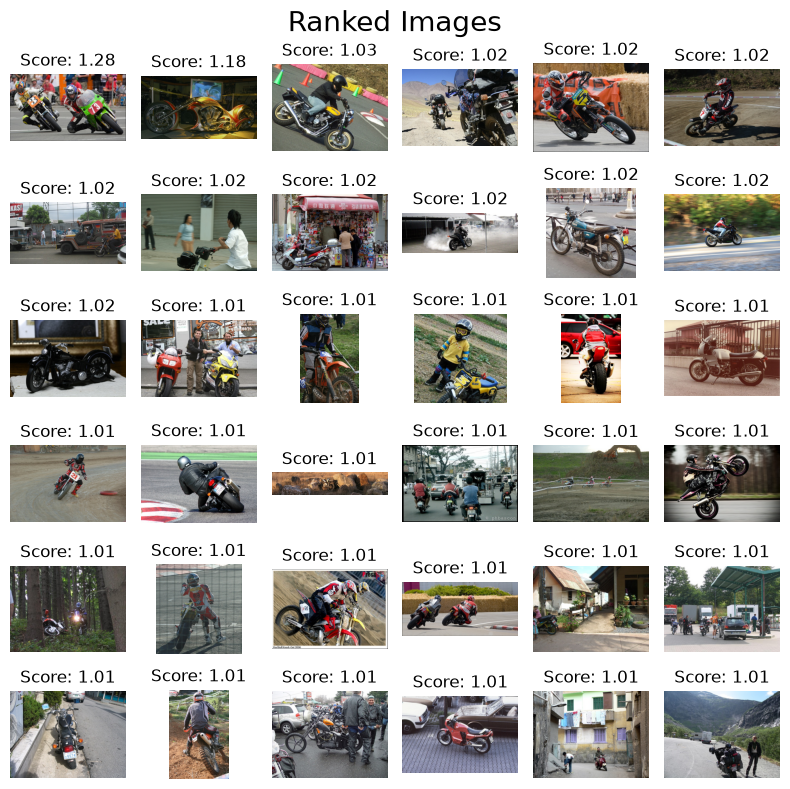

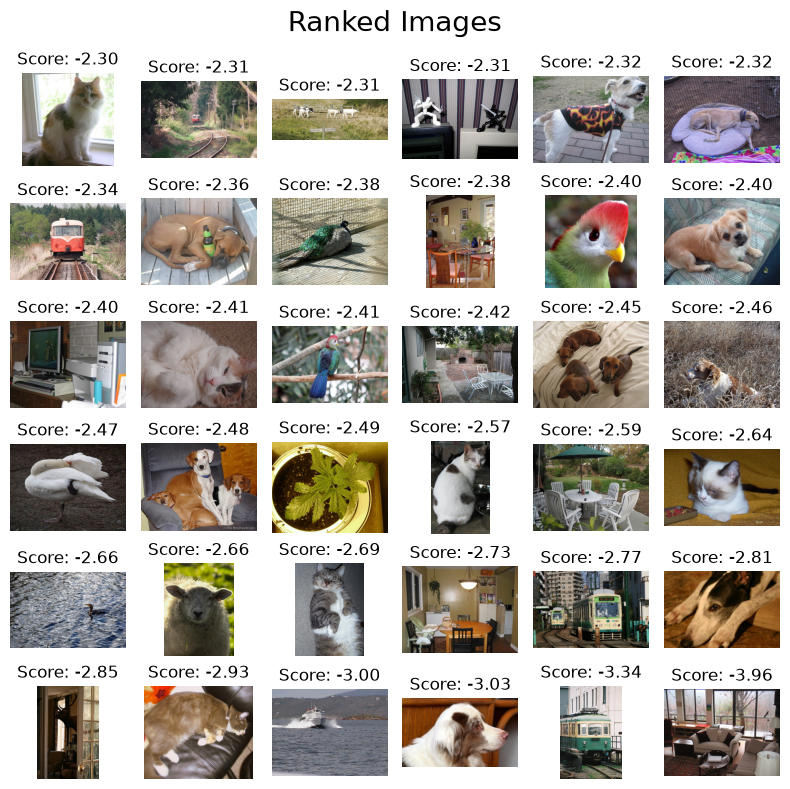

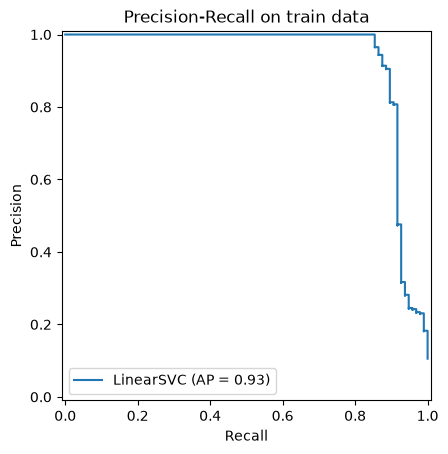

AP treino:    0.9329
AP validação: 0.5191


In [4]:
# Configure and train the linear SVM
start = time.perf_counter()
W, b = utils.train_svm(trainHist, trainLabels, C=10)
print(f"Tempo de treino do SVM: {time.perf_counter() - start:.2f} s")

# Evaluate the scores on the training data
scores = W @ trainHist.T + b

# Visualize the ranked list of images: topo do ranking
full_paths = [f"data/images/{name}.jpg" for name in trainNames]
displayRankedImageList(scores, full_paths, uniform=False, figzize=(8, 8))

# ... e fundo do ranking (os 36 scores mais baixos)
lowest = np.argsort(scores)[:36]
displayRankedImageList(scores[lowest], [full_paths[i] for i in lowest], uniform=False, figzize=(8, 8))

# Visualize the precision-recall curve
_ = displayPrecisionRecallCurve(trainLabels, scores, title="Precision-Recall on train data")

# Compare with validation (images the SVM never saw)
valScores = W @ valHist.T + b
print(f"AP treino:    {average_precision_score(trainLabels, scores):.4f}")
print(f"AP validação: {average_precision_score(valLabels, valScores):.4f}")

## Stage B: palavras visuais relevantes

O vetor `W` tem um peso por (tile, palavra), com layout `[tile0 | tile1 | tile2 | tile3]`.
`RelevantVisualWordsDisplay` espera um peso por palavra, por isso fazemos a média dos 4 tiles
com `W.reshape(4, -1).mean(axis=0)` (o mesmo raciocínio de `remove_spatial_information`).

Nota: a classe aplica internamente raiz + L2 ao histograma (Hellinger), por isso a ordenação das
palavras é aproximada para o SVM linear; serve para inspeção qualitativa.

In [5]:
assert "bovw" in encoding, "only works for BOVW encoding"

# Imagem de treino com o score mais alto
top_idx = np.argmax(scores)
print("Imagem:", trainNames[top_idx], "| label:", trainLabels[top_idx], "| score:", round(scores[top_idx], 3))

W_per_word = W.reshape(4, -1).mean(axis=0)   # (2048,) -> (512,): média de cada palavra nos 4 tiles

encoder = encoders.ImageEncoder(f"data/encoders/{encoding}.npz")
img = encoders.standarizeImage(f"data/images/{trainNames[top_idx]}.jpg")
rvwdisplay = RelevantVisualWordsDisplay(img, W_per_word, encoder)

import ipywidgets as widgets
@widgets.interact(rank=(0, len(rvwdisplay) - 1))
def display_relevant_visual_words(rank=0):
    rvwdisplay.plot(rank, figsize=(12, 8))

Imagem: 005173 | label: 1 | score: 1.276
Number of keypoints: 31537 Descriptor dimension: 128


interactive(children=(IntSlider(value=0, description='rank', max=511), Output()), _dom_classes=('widget-intera…

# Stage C: Classify the test images and assess the performance

Configuração escolhida → **retreinar com treino + validação** (mais dados, mesma configuração)
→ avaliar **uma única vez** no teste.

Inferência: 0.0007 ms por imagem (sem extração de features)
Correctly retrieved in the top 36: 30


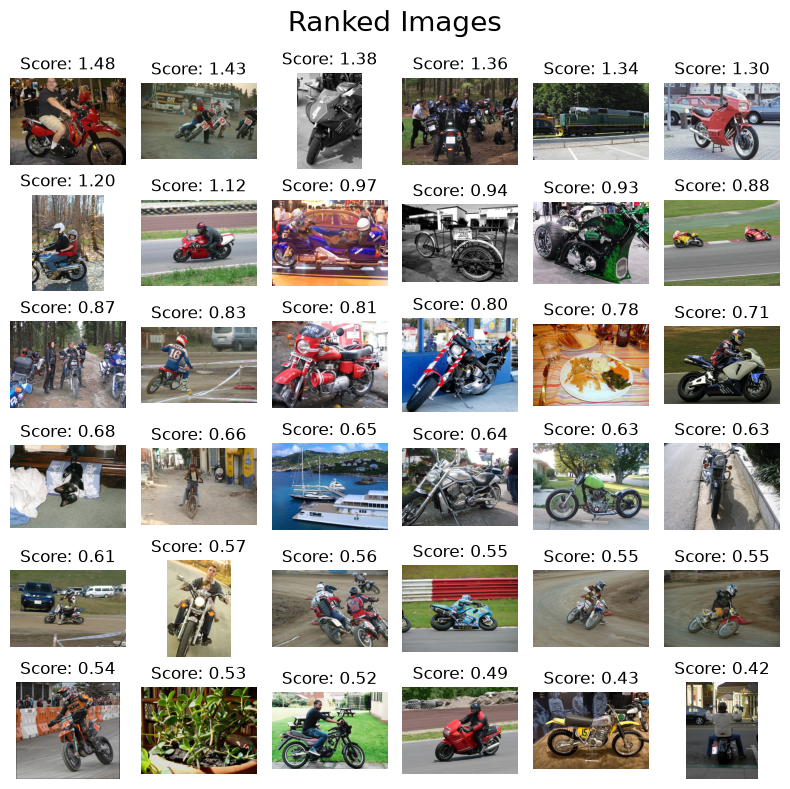

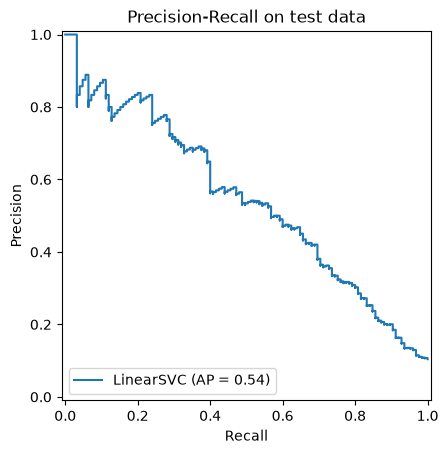

Average Precision (AP) on test data: 0.5440


In [6]:
# Final model: train + validation
finalHist = np.concatenate([trainHist, valHist])
finalLabels = np.concatenate([trainLabels, valLabels])
W, b = utils.train_svm(finalHist, finalLabels, C=10)

# Test the linear SVM
start = time.perf_counter()
testScores = W @ testHistograms.T + b
inference_time = time.perf_counter() - start
print(f"Inferência: {inference_time * 1000 / len(testLabels):.4f} ms por imagem (sem extração de features)")

# Print Results
perm = np.argsort(testScores)[::-1]
print('Correctly retrieved in the top 36: {:d}'.format(sum(testLabels[perm[:36]] > 0)))

# Visualize the ranked list of images
full_paths = [f"data/images/{name}.jpg" for name in testNames]
displayRankedImageList(testScores, full_paths, uniform=False, figzize=(8, 8))

# Visualize the precision-recall curve
*_, ap = displayPrecisionRecallCurve(testLabels, testScores, title="Precision-Recall on test data")
print(f"Average Precision (AP) on test data: {ap:.4f}")

## Stage C: o bias não muda o ranking

Somar a mesma constante `b` a todos os scores não altera a ordem das imagens, logo o AP é igual.

In [7]:
ap_with_bias = average_precision_score(testLabels, W @ testHistograms.T + b)
ap_without_bias = average_precision_score(testLabels, W @ testHistograms.T)
print(f"AP com bias:  {ap_with_bias:.6f}")
print(f"AP sem bias:  {ap_without_bias:.6f}")
print("Mesmo ranking:", np.array_equal(np.argsort(W @ testHistograms.T + b), np.argsort(W @ testHistograms.T)))

AP com bias:  0.543958
AP sem bias:  0.543958
Mesmo ranking: True
